# 02 · E2: YOLOv8s trained on KITTI (RQ1, RQ2)

The same YOLOv8s as E0, now **fine-tuned on KITTI's training drives** starting from the COCO weights (transfer
learning: 4 700 training images are too few to learn good visual features from scratch). Default settings,
640 px input. Compared with E0 this measures what KITTI training adds (RQ1); it is also the one-stage model in the
accuracy-versus-speed comparison with Faster R-CNN (RQ2).

**Why YOLOv8s.** A single-stage detector built for real time; the *s* (small, 11 M parameters) size is the usual
choice when a model has to run on a laptop or in-car GPU.

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## Data

In [2]:
tables = prepare_data()

copy images/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy labels/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: train 4699, val 1239, test 1543


## Training

Up to 40 epochs, batch 32, early stopping after 10 epochs without improvement on validation.

In [3]:
w, info = yolo_train("E2", "yolov8s.pt", DATA / "kitti.yaml", imgsz=640, epochs=40, batch=32)
info

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
training E2: yolov8s.pt, up to 40 epochs, imgsz 640, batch 32, changes: none
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/kitti.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/40      6.49G      1.202     0.8709       1.01        322        640: 100% ━━━━━━━━━━━━ 147/147 3.1it/s 47.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 4.0it/s 5.0s
                   all       1239       7296      0.685      0.419      0.467      0.273

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/40      6.79G        1.2     0.8637      1.008        352        640: 100% ━━━━━━━━━━━━ 147/147 3.0it/s 48.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 4.1it/s 4.9s
                   all       1239       7296      0.518      0.349      0.402      0.227

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/40      6.79G      1.207       0.85      1.017        309        640: 100% ━━━━━━━━━━━━ 147/147 3.0it/s 49.0s
                 Class     Images  Instances      Box

{'model': 'yolov8s.pt',
 'imgsz': 640,
 'batch': 32,
 'max_epochs': 40,
 'epochs_run': 12,
 'best_epoch': 2,
 'train_hours': 0.214,
 'settings': '{}',
 'data': 'kitti.yaml',
 'ultralytics_val_mAP50': 0.467,
 'ultralytics_val_mAP50_95': 0.27273}

## Training history

**How to read it.** Blue is the loss on the training images, orange on the validation images (drives the model
does not train on). While both fall, the model is learning things that generalise. When the validation loss
flattens or rises while the training loss keeps falling, the model has started to memorise the training drives
(over-fitting). The dashed line marks the epoch that was kept.

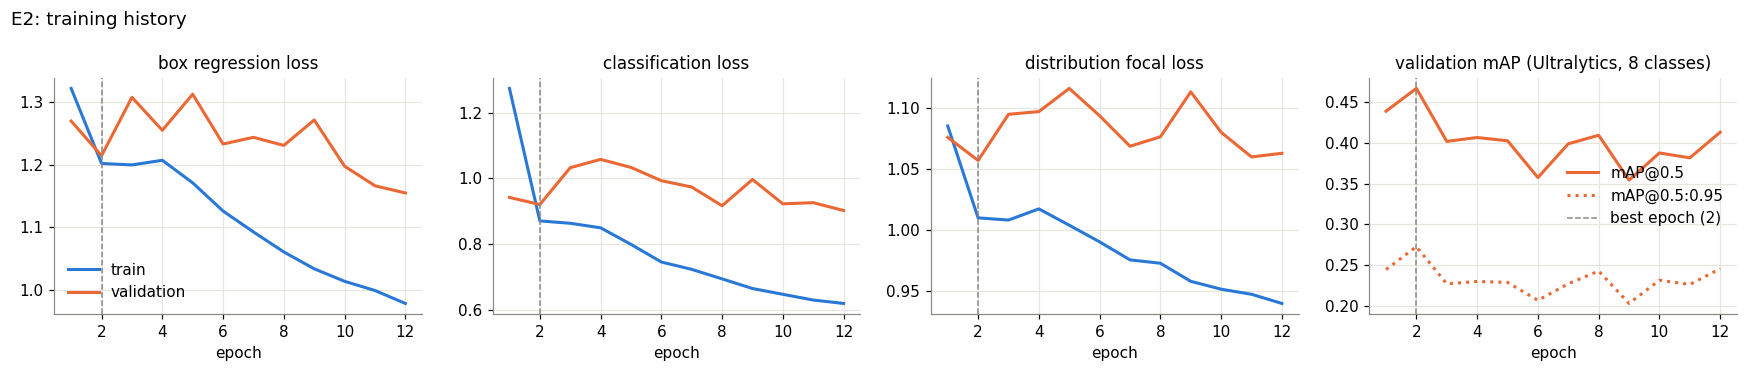

In [4]:
plot_yolo_history("E2")

## Validation

Our KITTI evaluator on the validation drives, using the kept (best) epoch.

In [5]:
val, val_table, _ = evaluate_model("E2", "yolo", w, tables, "val", imgsz=640)
headline(validation=val)

E2 on val:   0%|          | 0/78 [00:00<?, ?it/s]

,validation
"Primary (Car/Ped/Cyc, Moderate)",0.697
Car,0.957
Pedestrian,0.706
Cyclist,0.429
Easy (3 classes),0.852
Hard (3 classes),0.639
Car AP@0.7,0.882
"mAP@0.5, all 8 classes",0.465
"mAP@0.5:0.95, all 8 classes",0.261


## Test set (once)

The model is now fixed: every choice above was made on validation. It is scored once on the test set, i.e. on drives
it has never seen.

In [6]:
test, test_table, test_preds = evaluate_model("E2", "yolo", WEIGHTS / "E2.pt", tables, "test", imgsz=640)
headline(validation=val, test=test)

E2 on test:   0%|          | 0/97 [00:00<?, ?it/s]

,validation,test
"Primary (Car/Ped/Cyc, Moderate)",0.697,0.716
Car,0.957,0.965
Pedestrian,0.706,0.744
Cyclist,0.429,0.441
Easy (3 classes),0.852,0.744
Hard (3 classes),0.639,0.695
Car AP@0.7,0.882,0.867
"mAP@0.5, all 8 classes",0.465,0.429
"mAP@0.5:0.95, all 8 classes",0.261,0.250


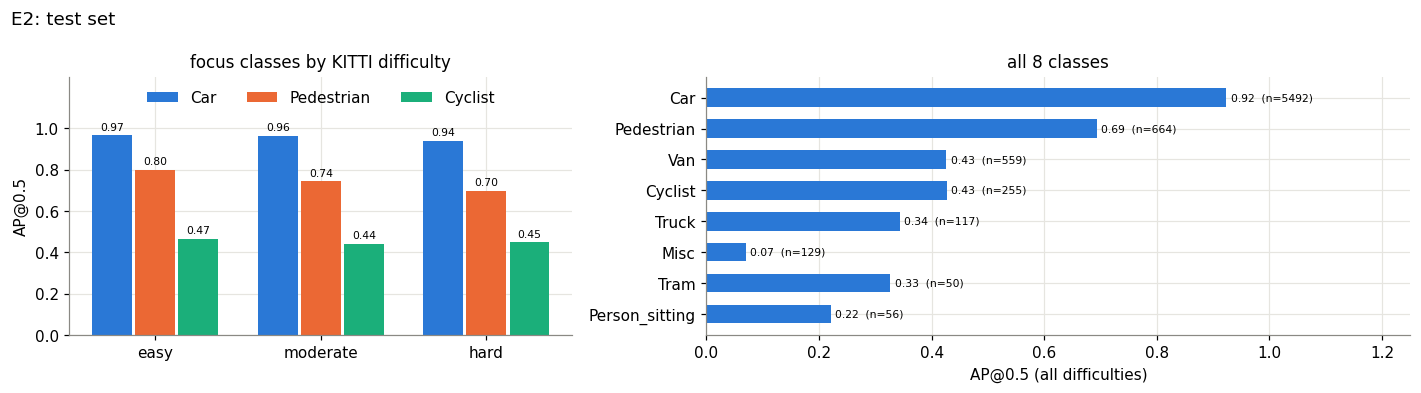

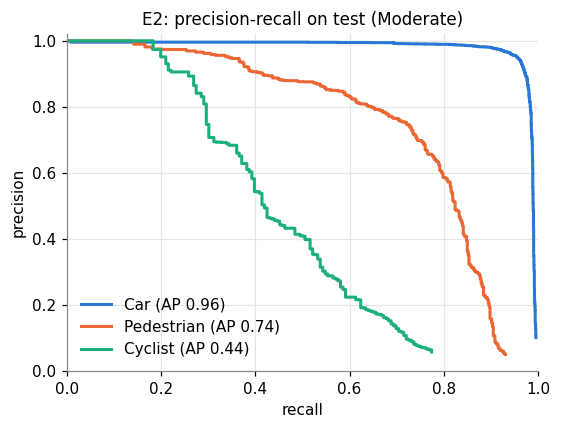

In [7]:
plot_per_class("E2", test_table, "test set")
plot_pr("E2", test_preds, tables, "test")

Ultralytics' own test evaluation, as a cross-check, with its normalised confusion matrix (rows: predicted class, columns: true class; *background* = missed objects / false alarms).

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,680 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4840.0±1109.6 MB/s, size: 846.1 KB)
val: Scanning /tmp/kitti/labels/test... 1543 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1543/1543 167.7it/s 9.2s
val: New cache created: /tmp/kitti/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 7.2it/s 13.5s
                   all       1543       7322      0.487      0.453      0.467      0.286
Speed: 0.4ms preprocess, 3.2ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /tmp/runs/E2_test


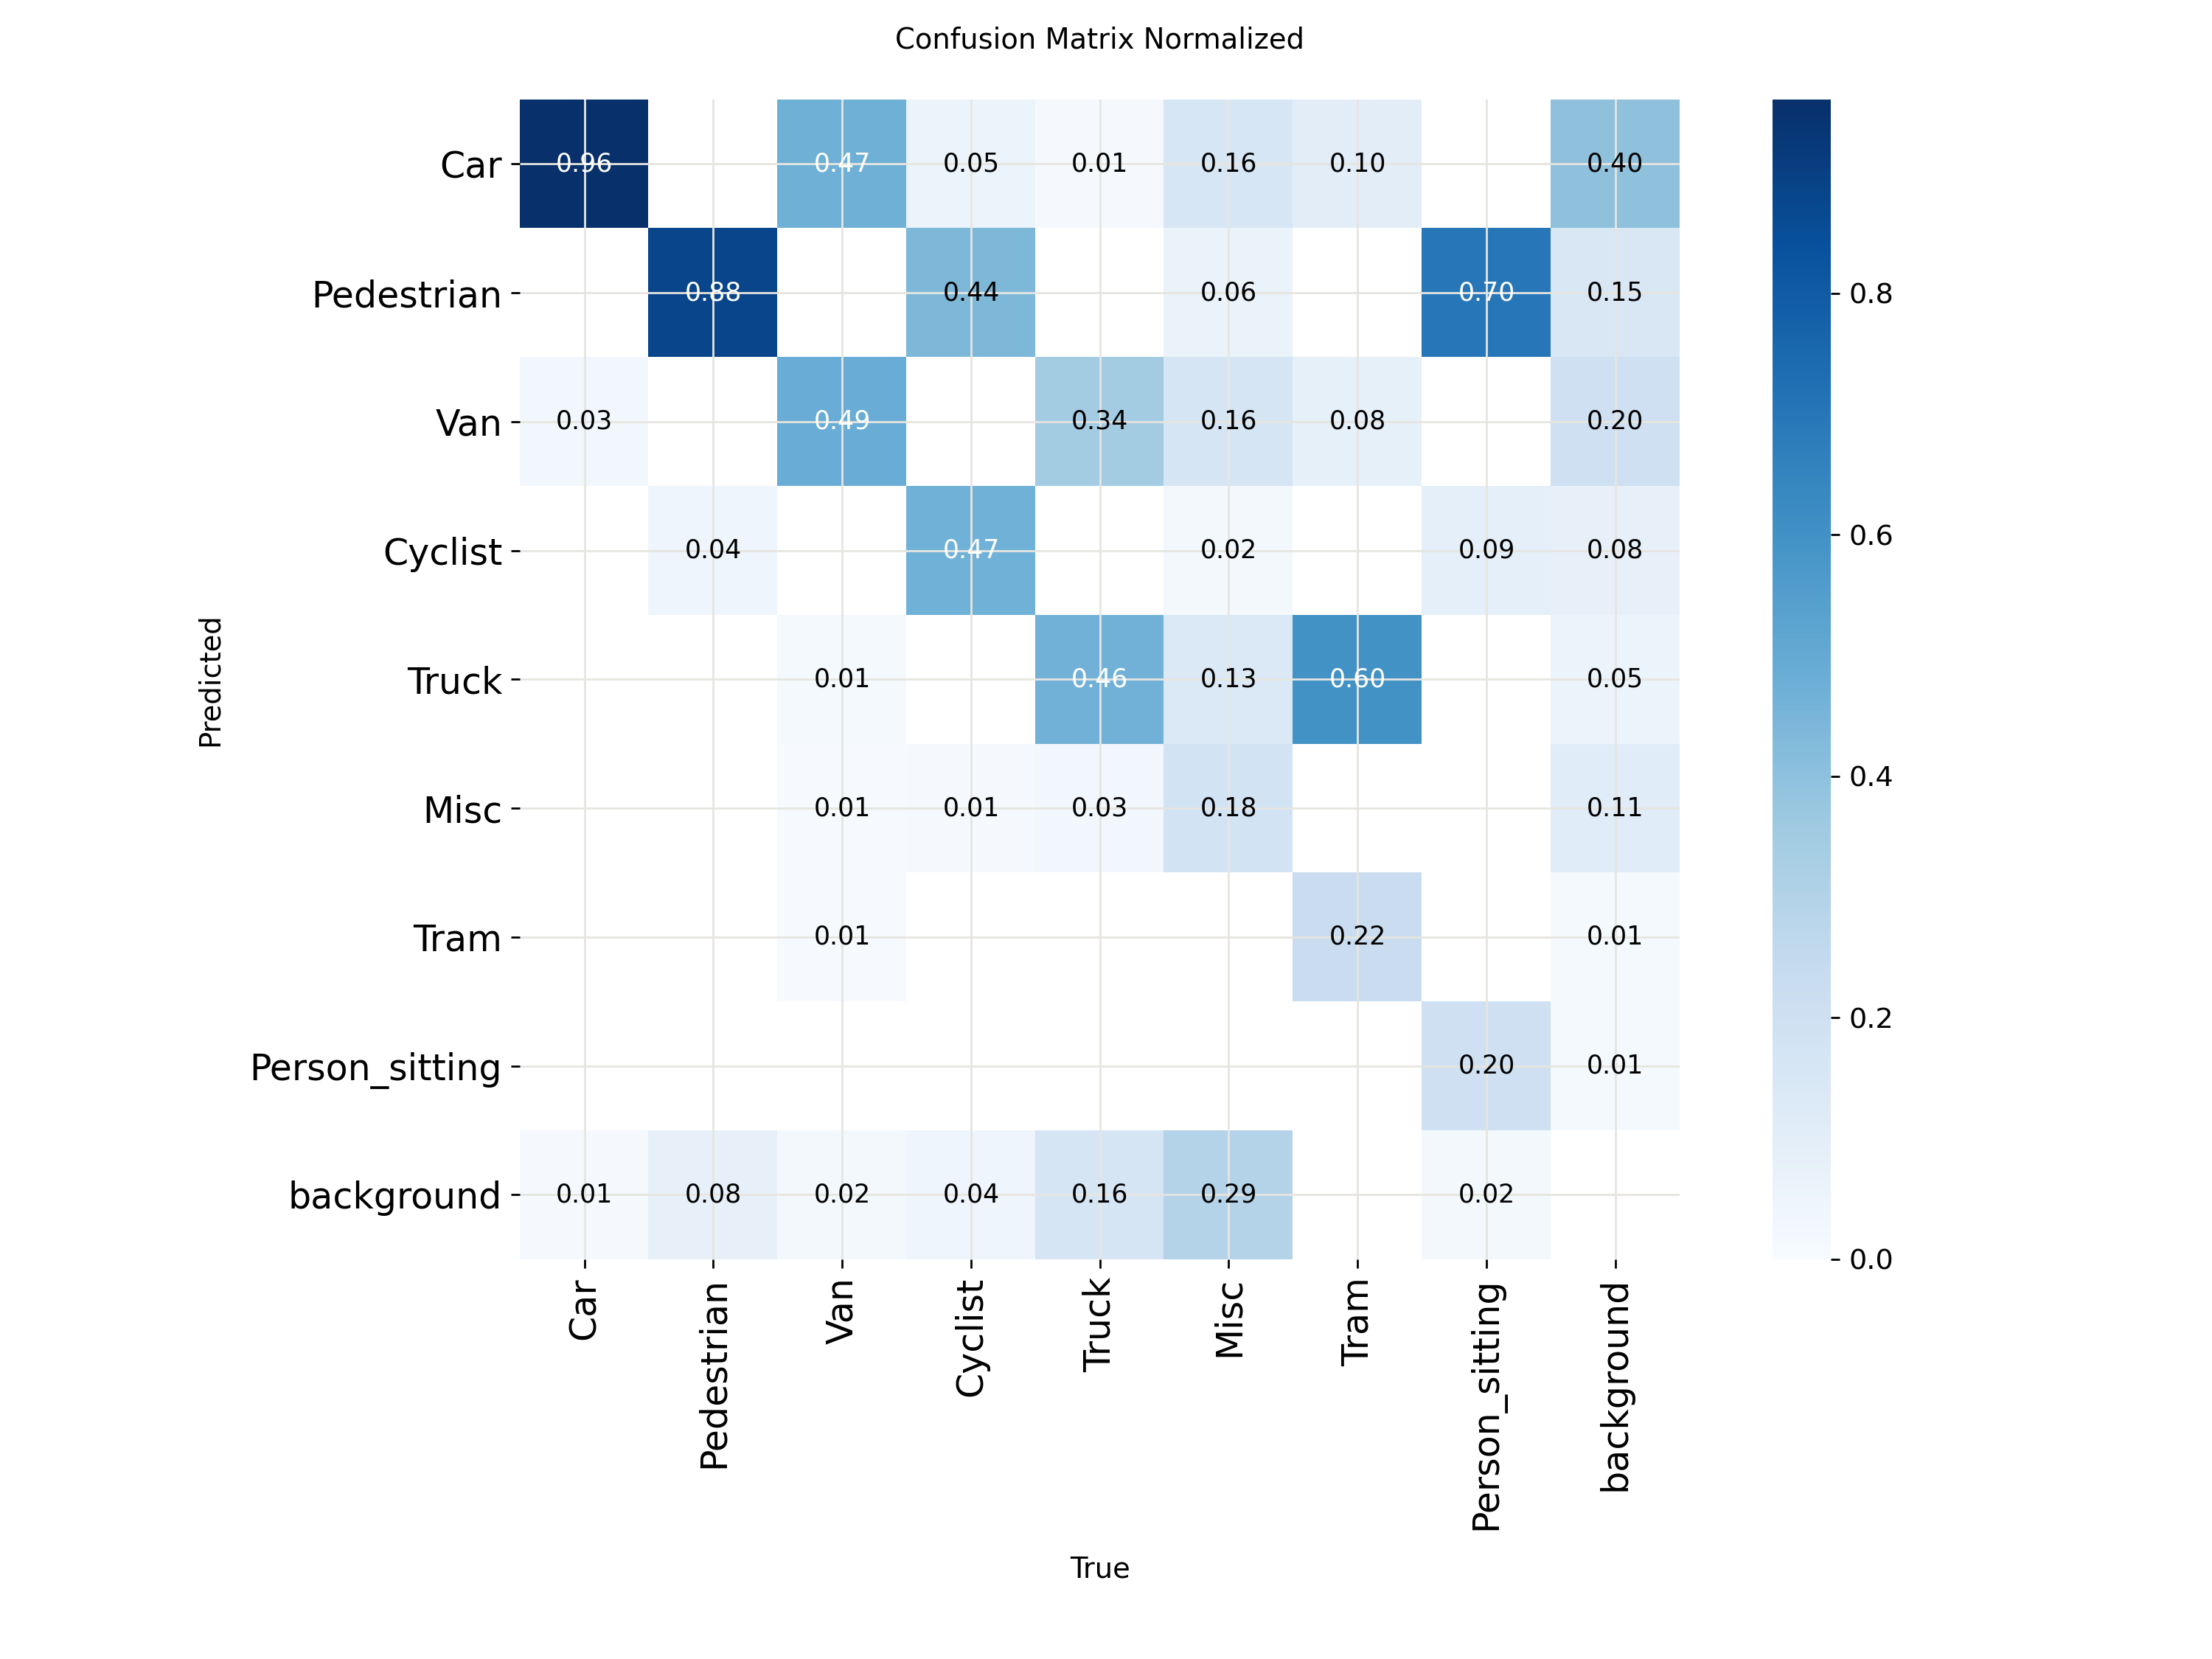

{'ultralytics_mAP50': 0.4674804422809498,
 'ultralytics_mAP50_95': 0.2856936597305344}

In [8]:
ultra = ultralytics_test_report("E2", WEIGHTS / "E2.pt", 640)
ultra

A few test images (the same ones in every notebook): detections with score ≥ 0.4 against the ground truth.

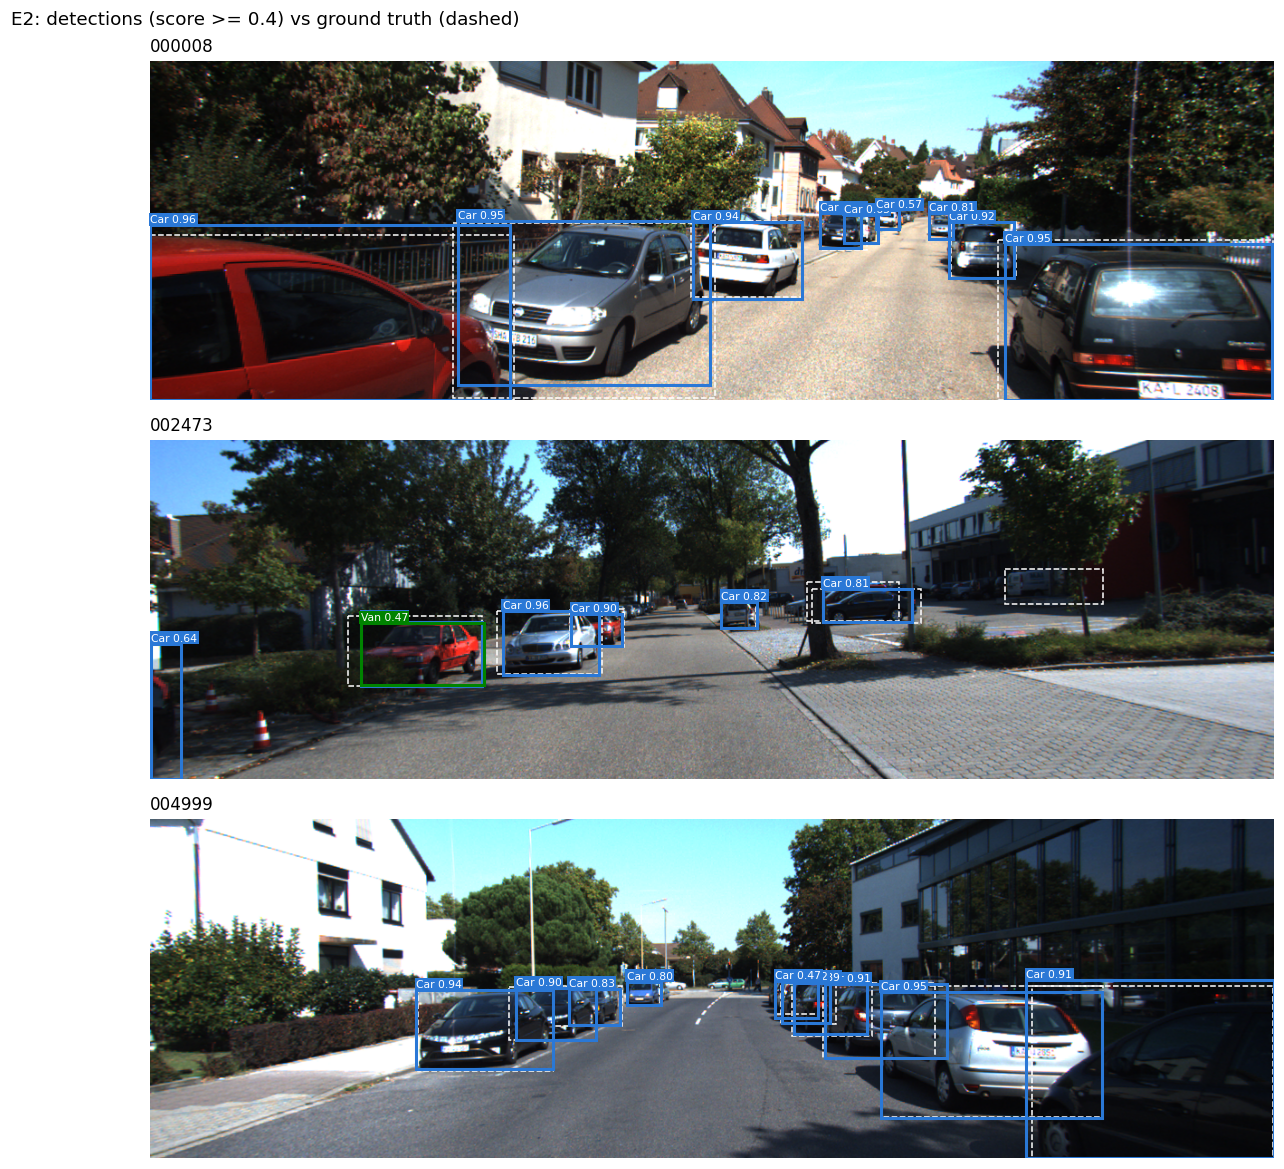

In [9]:
EXAMPLES = split_ids(tables[0], "test")[::max(1, len(split_ids(tables[0], "test")) // 3)][:3]
show_detections("E2", test_preds, tables, EXAMPLES)

## Observations

- **Primary metric: 0.697 validation, 0.716 test**, up from 0.542 for the COCO-only model (E0): **+0.174 on test**.
  Nearly all of the gain is in **cyclists (0.008 → 0.441)**, the class COCO does not have; pedestrians rise
  0.687 → 0.744 and cars barely move (0.930 → 0.965).
- **Overfitting to the training drives.** The best validation score came at **epoch 2 of 12**. After that the training
  losses keep falling while the validation losses stay flat, and early stopping ends the run 10 epochs later.
  With only 141 drives, the model quickly learns the training scenes rather than the task.
- Cyclists remain the weakest class (0.441): they are rare (255 in the whole test set, against 5,492 cars) and small at 640 px. Notebook 04 tests
  the two obvious fixes, a larger input size and oversampling rare classes.

## Record

The experiment's row of the experiment log (`results/E2/record.json`).

In [10]:
rec = save_record("E2", "YOLOv8s fine-tuned on KITTI, 640 px", "RQ1, RQ2", val=val, test=test, **info, **{f'test_{k}': v for k, v in ultra.items()})
pd.Series(rec).to_frame("value")

,value
exp_id,E2
description,"YOLOv8s fine-tuned on KITTI, 640 px"
research_question,"RQ1, RQ2"
model,yolov8s.pt
imgsz,640
batch,32
max_epochs,40
epochs_run,12
best_epoch,2
train_hours,0.214
